# CSE 4095 — Class 2: Classification
Use AI as a coding agent, but inspect and explain every major decision.

## 1. Load the Class 1 dataset
Upload `class1_student_habits.csv`, import Pandas, load it as `df`, and inspect the first rows.

In [1]:
# TODO: load the CSV
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("class1_student_habits.csv")

df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,NaN,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,NaN,Yes,12,75.7,68.5


## 2. Create the target
Create `high_exam_score`: Yes if `exam_score >= 80`, otherwise No. Then inspect class counts.

Class counts:
high_exam_score
No     151
Yes     99
Name: count, dtype: int64

Class percentages:
high_exam_score
No     60.4
Yes    39.6
Name: proportion, dtype: float64


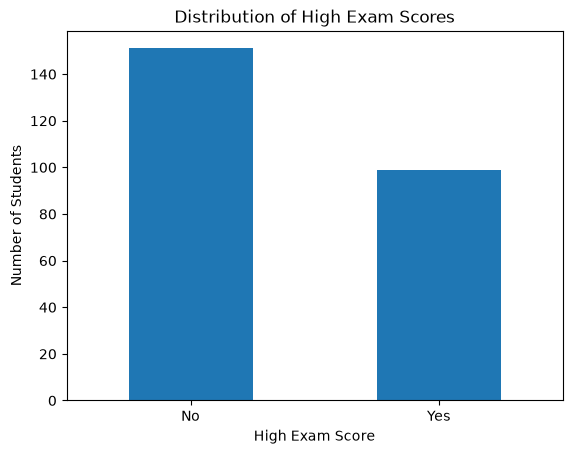

In [2]:
# TODO: create target and inspect class balance
# Create the classification target
df["high_exam_score"] = "No"
df.loc[df["exam_score"] >= 80, "high_exam_score"] = "Yes"

# Class counts
class_counts = df["high_exam_score"].value_counts()
print("Class counts:")
print(class_counts)

# Class percentages
class_percentages = df["high_exam_score"].value_counts(normalize=True) * 100
print("\nClass percentages:")
print(class_percentages)

# Visualize the class distribution
class_counts.plot(kind="bar")

plt.title("Distribution of High Exam Scores")
plt.xlabel("High Exam Score")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

Questions:

Why is predicting exam_score a regression problem? 
- Predicting exam_score is a regression problem because exam_score is a numerical value that can take many possible values, such as 64.6, 81.5, or 92.0. 

Why is predicting high_exam_score a classification problem? 
- Predicting high_exam_score is a classification problem because the output belongs to one of two categories: Yes or No. 

How many students belong to each class? 
- There are 151 students in the No class and 99 students in the Yes class. 

What percentage of students belong to each class? 
- The No class contains 60.4% of the students, while the Yes class contains 39.6%.

## 3. Choose X and y
Use only legitimate features. Explain in Markdown why `student_id` and `exam_score` are excluded.

In [3]:
# TODO: define feature columns, X, and y
# Required features for the primary model
features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes"
]

X = df[features]
y = df["high_exam_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (250, 7)
y shape: (250,)


,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes
0,1.3,7.7,71.8,8,Strong,No,0
1,9.4,6.6,74.2,14,NaN,Yes,52
2,11.2,6.1,70.3,15,Some,No,7
3,10.8,7.6,77.1,16,Strong,No,12
4,8.0,5.6,89.7,15,NaN,Yes,12


Questions:

Explain why student_id should normally not be used as a predictor.
More importantly, explain why using exam_score to predict high_exam_score would be a serious problem.
- `student_id` should normally not be used as a predictor because it is just an identifier for each student. It does not represent a meaningful characteristic that should help predict whether a student will have a high exam score. Using `exam_score` to predict `high_exam_score` would be a serious problem because `high_exam_score` was created directly from `exam_score`. The target is `Yes` when `exam_score >= 80` and `No` otherwise. If `exam_score` is included as an input feature, the model is essentially being given the answer it is supposed to predict. This is called target leakage, and it would make the model's performance look unrealistically good.

In [4]:
## Split the Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set size:", len(X_train))
print("Test set size:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training set size: 200
Test set size: 50

Training class distribution:
high_exam_score
No     60.5
Yes    39.5
Name: proportion, dtype: float64

Test class distribution:
high_exam_score
No     60.0
Yes    40.0
Name: proportion, dtype: float64


Questions:

What is the purpose of the training set?
- The purpose of the training set is to give the model data that it can learn from. The model uses the training data to learn patterns between the input features and `high_exam_score`.

What is the purpose of the test set?
- The purpose of the test set is to evaluate how well the trained model works on data it did not see during training. This gives a better idea of how the model may perform on new students.

What does stratification do?
- Stratification keeps the class proportions similar in both the training and test sets. In this case, the full dataset has about 60% `No` and 40% `Yes`, and the training and test sets have very similar percentages.

Why shouldn't we train the model using the test data?
- We should not train the model using the test data because the test set is supposed to be unseen data used only for evaluation. If the model learns from the test set, the evaluation would no longer be a fair measure of how well the model performs on new data.

## 4. Baseline
Calculate the majority-class baseline accuracy before training a model.

In [5]:
# TODO: calculate baseline
# Find the majority class in the training data
majority_class = y_train.value_counts().idxmax()

# Predict the majority class for every student in the test set
baseline_predictions = [majority_class] * len(y_test)

# Calculate baseline accuracy
baseline_accuracy = (baseline_predictions == y_test).mean()

print("Majority class:", majority_class)
print("Baseline accuracy:", baseline_accuracy)


Majority class: No
Baseline accuracy: 0.6


Questions:

What is the majority class?
- The majority class is No, because there are more students with high_exam_score = No than Yes in the training data.

What accuracy does the majority-class baseline achieve?
- The majority-class baseline achieves an accuracy of 0.60, or 60%. This means that if we always predicted No for every student in the test set, we would be correct 60% of the time.

Why is this baseline useful?
- The baseline gives us a simple result to compare our Logistic Regression model against. If the trained model cannot perform better than the 60% baseline, then it may not be learning anything more useful than simply predicting the most common class.

## 5. Train/test split and preprocessing
Ask your AI agent for a pipeline that handles numerical/categorical missing values and one-hot encoding.

In [ ]:
## Numerical and Categorical Features

numerical_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes"
]

categorical_features = [
    "prior_programming_experience",
    "study_group"
]

In [7]:
# TODO: imports, preprocessing, and train/test split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Questions:

Why do categorical variables need to be converted before Logistic Regression can use them?
- Logistic Regression works with numerical values, so text categories such as Yes, No, Some, or Strong need to be converted into numbers before the model can use them.

What does one-hot encoding do?
- One-hot encoding creates separate columns for the different categories and represents each category using 0s and 1s. This lets the model use categorical information without treating the categories as if they have a numerical order.

Why do we need to handle missing values?
- Missing values need to be handled because many machine-learning models cannot train properly when the input data contains missing entries. Imputation fills in those missing values using a reasonable replacement, such as the median for numerical data or the most frequent category for categorical data.

What does StandardScaler do?
- StandardScaler changes numerical features so they are on a similar scale. It centers each feature around a mean of about 0 and gives it a standard deviation of about 1, which can help Logistic Regression work more effectively when features use very different units or ranges.

Questions:

Why might scaling be useful for Logistic Regression?
- Scaling is useful because the numerical features are measured in different units and can have very different ranges. Standardizing them puts the features on a similar scale, which can help Logistic Regression train more consistently.

Does standardization mean that all original values become numbers between 0 and 1?
- No. Standardization does not force values to be between 0 and 1. Instead, it changes the values so the feature has a mean of about 0 and a standard deviation of about 1. Some standardized values can be negative or greater than 1.

Why should the test set not be used to calculate the mean and standard deviation used for scaling?
- The test set should remain unseen until evaluation. If we use the test set to calculate the mean and standard deviation, information from the test data would influence the preprocessing. This would be a form of data leakage and could make the model's evaluation less fair.

## 6. Logistic regression
Fit the model using training data only.

In [8]:
# TODO: build and fit pipeline
from sklearn.linear_model import LogisticRegression

# Build the full pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression())
])

# Train the pipeline using only the training data
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['study_hours_per_week','sleep_hours_per_night','attendance_rate',..., 'prior_programming_experience','study_group','commute_minutes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are droppe

Questions:

What does .fit() do?
- .fit() trains the pipeline using the training data. It first learns the preprocessing steps from X_train, then uses the processed training data to train the Logistic Regression model.

What is learned from the training data?
- The preprocessing steps learn things such as the values used to fill in missing data and the mean and standard deviation used for scaling. The Logistic Regression model then learns the relationships between the processed features and the target classes, Yes and No.

Why is it useful to put preprocessing and the classifier into one pipeline?
- A pipeline keeps all of the preprocessing and model-training steps together and applies them in the correct order. This helps make sure the same transformations are applied consistently to both training and test data and reduces the chance of mistakes or data leakage.

## 7. Evaluate
Calculate accuracy, confusion matrix, precision, and recall. Compare accuracy with the baseline.

In [10]:
# TODO: evaluate test predictions
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Make predictions on the test set
y_pred = model.predict(X_test)

# Get predicted probabilities
y_prob = model.predict_proba(X_test)

# Get the probability of the "Yes" class
yes_index = list(model.classes_).index("Yes")
yes_probabilities = y_prob[:, yes_index]

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

# Display results
print("Accuracy:", accuracy)
print("Precision for Yes:", precision)
print("Recall for Yes:", recall)

print("\nConfusion Matrix:")
print(cm)

print("\nMajority-class baseline accuracy:", baseline_accuracy)
print("Logistic Regression accuracy:", accuracy)

# Compare model accuracy with the baseline
if accuracy > baseline_accuracy:
    print("The Logistic Regression model performed better than the baseline.")
elif accuracy == baseline_accuracy:
    print("The Logistic Regression model performed the same as the baseline.")
else:
    print("The Logistic Regression model performed worse than the baseline.")

Accuracy: 0.84
Precision for Yes: 0.8333333333333334
Recall for Yes: 0.75

Confusion Matrix:
[[27  3]
 [ 5 15]]

Majority-class baseline accuracy: 0.6
Logistic Regression accuracy: 0.84
The Logistic Regression model performed better than the baseline.


Questions:

Explain the difference between predict() and predict_proba():
- predict() gives the final predicted class for each student, such as Yes or No.
predict_proba() gives the estimated probability for each possible class. In this assignment, we are mainly interested in the probability of the Yes class.

What does a predicted probability near 0.5 suggest?
- A probability near 0.5 means the model is relatively uncertain. It sees the student as being close to the boundary between Yes and No.

What about a probability near 0.95?
- A probability near 0.95 for Yes means the model is very confident that the student belongs to the Yes class. It is estimating about a 95% probability of a high exam score.

Questions:

Accuracy
- The model’s accuracy is 0.84, or 84%. This means that 84% of all test predictions were correct.

Precision
- The precision for Yes is about 0.83, or 83.3%. This means that among the students the model predicted would have a high exam score, about 83.3% actually did.

Recall
- The recall for Yes is 0.75, or 75%. This means that among the students who actually had a high exam score, the model correctly identified 75% of them.

Comparison with the baseline
- The majority-class baseline accuracy was 60%, while the Logistic Regression model achieved 84% accuracy. This means the Logistic Regression model performed better than simply predicting the majority class, No, for every student.

## 8. Inspect individual predictions
Create a small table with actual class, predicted class, and predicted probability.

In [14]:
# TODO: inspect predictions
# Get the four values from the confusion matrix
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


# Make a copy of the original test-set feature values
error_results = X_test.copy()

# Add the actual and predicted classes
error_results["Actual"] = y_test
error_results["Predicted"] = y_pred

# False positives:
# actual class is No, but the model predicted Yes
false_positives = error_results[
    (error_results["Actual"] == "No") &
    (error_results["Predicted"] == "Yes")
]

# False negatives:
# actual class is Yes, but the model predicted No
false_negatives = error_results[
    (error_results["Actual"] == "Yes") &
    (error_results["Predicted"] == "No")
]

print("False Positives:")
display(false_positives)

print("False Negatives:")
display(false_negatives)

True Negatives: 27
False Positives: 3
False Negatives: 5
True Positives: 15
False Positives:


,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,Actual,Predicted
175,12.7,7.3,74.0,13,NaN,No,15,No,Yes
169,9.4,7.5,98.3,19,NaN,No,45,No,Yes
156,7.5,6.9,91.9,23,NaN,Yes,21,No,Yes


False Negatives:


,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,Actual,Predicted
113,10.3,6.0,89.5,9,Some,No,38,Yes,No
140,9.4,7.0,82.8,13,Some,No,31,Yes,No
37,5.5,7.1,78.3,22,Some,Yes,19,Yes,No
89,NaN,6.2,72.7,15,Strong,No,28,Yes,No
99,5.7,7.2,82.7,19,NaN,No,14,Yes,No


Questions:

Part 10 — Understand the Confusion Matrix.

How many false positives did the model produce?
- The model produced 3 false positives.

How many false negatives did the model produce?
- The model produced 5 false negatives.

What is the difference between these two types of errors in this problem?
- A false negative means the model predicted that a student would not have a high exam score (No), but the student's actual class was Yes. A false positive means the model predicted that a student would have a high exam score (Yes), but the student's actual class was No.

Part 11 — Inspect Individual Errors

Do you notice anything interesting about the mistakes?
- Some of the false positives had features that could reasonably look similar to students in the Yes class. For example, some had relatively high attendance rates or completed many practice problems. Some of the false negatives had more moderate values for study hours, attendance, or practice problems, even though their actual class was Yes.
There are also missing values in some of the misclassified students, especially for prior_programming_experience and one case of study_hours_per_week.
 
Can you form a hypothesis about why the model may have found some of these students difficult to classify?
- A possible hypothesis is that some students have a combination of features that overlaps with the patterns of the opposite class. Since Logistic Regression uses several features together, students whose values are close to the model's decision boundary may be harder to classify correctly. Missing values that had to be imputed may also make some cases harder to distinguish.

## 9. Controlled leakage experiment
Temporarily include `exam_score` as a feature, compare results, and explain why this experiment is invalid as a real model.

In [15]:
# TODO: leakage experiment
# Create a separate feature set for the leakage experiment
X_leak = X.copy()
X_leak["exam_score"] = df["exam_score"]

# Use the same train/test rows as the legitimate model
X_leak_train = X_leak.loc[X_train.index]
X_leak_test = X_leak.loc[X_test.index]

# Numerical features now include exam_score
numerical_features_leak = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
    "exam_score"
]

categorical_features_leak = [
    "prior_programming_experience",
    "study_group"
]

# Numerical preprocessing for leakage experiment
numerical_transformer_leak = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing for leakage experiment
categorical_transformer_leak = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_leak = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_leak, numerical_features_leak),
        ("cat", categorical_transformer_leak, categorical_features_leak)
    ]
)

# Separate model for the leakage experiment
leakage_model = Pipeline(steps=[
    ("preprocessor", preprocessor_leak),
    ("classifier", LogisticRegression())
])

# Train using only the same training rows
leakage_model.fit(X_leak_train, y_train)

# Predict using the leakage model
y_pred_leak = leakage_model.predict(X_leak_test)

# Calculate leakage-model accuracy
leakage_accuracy = accuracy_score(y_test, y_pred_leak)

print("Legitimate model accuracy:", accuracy)
print("Leakage model accuracy:", leakage_accuracy)

Legitimate model accuracy: 0.84
Leakage model accuracy: 0.98


Questions:

What happened to the accuracy?
- The accuracy increased compared with the legitimate model. This happened because exam_score gives the model information that is directly connected to the target.

Why did this happen?
- high_exam_score was created directly from exam_score using the rule exam_score >= 80. By including exam_score as an input feature, the model is being given information that almost directly reveals the correct class.

Why is this model invalid even if its accuracy is extremely high?
- The model is invalid because this is target leakage. It is using a feature that contains the answer it is supposed to predict. The high accuracy is therefore misleading and does not represent a fair or realistic prediction task.

Quiz Average Experiment:


In [16]:
# Create a separate feature set for the quiz_average experiment
X_quiz = X.copy()
X_quiz["quiz_average"] = df["quiz_average"]

# Reuse the exact same training and test rows
X_quiz_train = X_quiz.loc[X_train.index]
X_quiz_test = X_quiz.loc[X_test.index]

# Numerical features now include quiz_average
numerical_features_quiz = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
    "quiz_average"
]

categorical_features_quiz = [
    "prior_programming_experience",
    "study_group"
]

# Numerical preprocessing
numerical_transformer_quiz = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_quiz = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_quiz = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_quiz, numerical_features_quiz),
        ("cat", categorical_transformer_quiz, categorical_features_quiz)
    ]
)

# Build a separate Logistic Regression pipeline
quiz_model = Pipeline(steps=[
    ("preprocessor", preprocessor_quiz),
    ("classifier", LogisticRegression())
])

# Train using the same training rows
quiz_model.fit(X_quiz_train, y_train)

# Make predictions on the same test rows
y_pred_quiz = quiz_model.predict(X_quiz_test)

# Calculate evaluation metrics
quiz_accuracy = accuracy_score(y_test, y_pred_quiz)

quiz_precision = precision_score(
    y_test,
    y_pred_quiz,
    pos_label="Yes"
)

quiz_recall = recall_score(
    y_test,
    y_pred_quiz,
    pos_label="Yes"
)

# Compare with the original legitimate model
print("Original model:")
print("Accuracy:", accuracy)
print("Precision for Yes:", precision)
print("Recall for Yes:", recall)

print("\nQuiz-average model:")
print("Accuracy:", quiz_accuracy)
print("Precision for Yes:", quiz_precision)
print("Recall for Yes:", quiz_recall)

Original model:
Accuracy: 0.84
Precision for Yes: 0.8333333333333334
Recall for Yes: 0.75

Quiz-average model:
Accuracy: 0.82
Precision for Yes: 0.7894736842105263
Recall for Yes: 0.75


Questions:

Did quiz_average improve the model?
- No. Adding quiz_average did not improve the model overall. The accuracy decreased from 84% to 82%.

Which metrics changed?
- Accuracy decreased from 0.84 to 0.82, and precision for Yes decreased from about 0.833 to 0.789. Recall for Yes stayed the same at 0.75.

Was your original prediction correct?
- If your original prediction was that adding quiz_average would improve the model, then no, the prediction was not supported by the results. The model's accuracy and precision decreased slightly, while recall stayed the same.

## 10. Your experiment
Change one legitimate modeling decision. Write your prediction before running it, then compare results.

Hypothesis:
- I think removing sleep_hours_per_night will slightly reduce the model’s performance because sleep may contain useful information for predicting whether a student has a high exam score.

In [17]:
# TODO: student-designed experiment
# Create a separate feature set without sleep_hours_per_night
features_no_sleep = [
    "study_hours_per_week",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes"
]

X_no_sleep = df[features_no_sleep]

# Reuse the exact same training and test rows
X_no_sleep_train = X_no_sleep.loc[X_train.index]
X_no_sleep_test = X_no_sleep.loc[X_test.index]

# Numerical and categorical feature lists
numerical_features_no_sleep = [
    "study_hours_per_week",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes"
]

categorical_features_no_sleep = [
    "prior_programming_experience",
    "study_group"
]

# Numerical preprocessing
numerical_transformer_no_sleep = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_no_sleep = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_no_sleep = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_no_sleep, numerical_features_no_sleep),
        ("cat", categorical_transformer_no_sleep, categorical_features_no_sleep)
    ]
)

# Build a separate Logistic Regression model
no_sleep_model = Pipeline(steps=[
    ("preprocessor", preprocessor_no_sleep),
    ("classifier", LogisticRegression())
])

# Train using the same training rows
no_sleep_model.fit(X_no_sleep_train, y_train)

# Make predictions on the same test rows
y_pred_no_sleep = no_sleep_model.predict(X_no_sleep_test)

# Calculate evaluation metrics
no_sleep_accuracy = accuracy_score(y_test, y_pred_no_sleep)

no_sleep_precision = precision_score(
    y_test,
    y_pred_no_sleep,
    pos_label="Yes"
)

no_sleep_recall = recall_score(
    y_test,
    y_pred_no_sleep,
    pos_label="Yes"
)

# Compare with the original legitimate model
print("Original model:")
print("Accuracy:", accuracy)
print("Precision for Yes:", precision)
print("Recall for Yes:", recall)

print("\nModel without sleep_hours_per_night:")
print("Accuracy:", no_sleep_accuracy)
print("Precision for Yes:", no_sleep_precision)
print("Recall for Yes:", no_sleep_recall)

Original model:
Accuracy: 0.84
Precision for Yes: 0.8333333333333334
Recall for Yes: 0.75

Model without sleep_hours_per_night:
Accuracy: 0.8
Precision for Yes: 0.7777777777777778
Recall for Yes: 0.7


Hypothesis
- I think removing sleep_hours_per_night will slightly reduce the model’s performance because sleep may contain useful information for predicting whether a student has a high exam score.

What happened?
- After removing sleep_hours_per_night, the model’s accuracy decreased from 0.84 to 0.80. Precision for Yes decreased from about 0.833 to 0.778, and recall for Yes decreased from 0.75 to 0.70.

Did the evidence support the hypothesis?
- Yes. The results supported the hypothesis because all three evaluation metrics decreased after sleep_hours_per_night was removed. This suggests that the feature was providing some useful predictive information to the model, although this does not mean sleep itself caused the exam outcomes.

## Conclusion
Write a short evidence-based conclusion and AI Reflection here.


## Part 15 — AI Reflection

For this assignment, I used AI throughout the process to help me understand the scikit-learn workflow and organize the code correctly in the starter notebook. The AI helped me create the preprocessing pipeline using `SimpleImputer`, `StandardScaler`, `OneHotEncoder`, and `ColumnTransformer`. It also explained Logistic Regression, helped me interpret the confusion matrix, and suggested the experiment where I removed `sleep_hours_per_night` to see how the model's performance changed.

What did the AI suggest?  
- The AI suggested how to organize the preprocessing and Logistic Regression pipeline, how to evaluate the model using accuracy, precision, recall, and a confusion matrix, and how to inspect false positives and false negatives. It also suggested removing `sleep_hours_per_night` for my additional experiment.

Did you accept the suggestion?
- Yes. I used these suggestions in my notebook, but I worked through them step by step instead of asking the AI to complete the entire assignment at once.

How did you verify that the suggestion was reasonable?  
- I ran each section of the code and checked the outputs. I also compared the code and results with the assignment requirements. For example, I made sure preprocessing was based on the training data, used the same train/test split for the experiments, and compared the Logistic Regression model with the majority-class baseline.

Did the AI make any assumption that you needed to question or correct? 
- Yes. At one point, the AI gave prediction and evaluation code as several separate pieces that did not clearly match the order of my starter notebook. I had to clarify the notebook structure and reorganize the code so the predictions were created before the evaluation metrics and the existing notebook sections were preserved.

What did you learn?
- I learned how a complete classification workflow works, including creating a target, splitting the data, preprocessing numerical and categorical features, training Logistic Regression, making predictions, and evaluating the results. I also learned why target leakage is a serious problem and why a model with very high accuracy is not automatically a valid model. The experiments also showed me that adding a feature does not always improve a model and that removing a feature can change accuracy, precision, and recall.

## Conclusion

The legitimate Logistic Regression model achieved **84% accuracy**, compared with the **60% majority-class baseline**. Its precision for `Yes` was about **83.3%**, and its recall for `Yes` was **75%**. The target-leakage experiment produced much higher accuracy, but that model was invalid because it used `exam_score`, which directly determines the target. Adding `quiz_average` did not improve the original model, while removing `sleep_hours_per_night` reduced accuracy, precision, and recall. Overall, the experiments showed that model performance should be evaluated along with whether the features and experimental setup are valid.